# Who delivers under pressure — SupeRR Selector S2

This notebook reproduces the headline analysis from the committed results, so it runs anywhere in
the repo without the 1.2 GB of raw data. The full pipeline that produced these files is in
`scripts/` (see the README).

**The question:** can we separate players who rise when the game is on the line from those who fade?

**The approach in one line:** a win-probability model says how much each ball can swing the match
(its *Leverage Index*); the busiest 20% of balls are "pressure" balls; players are then measured on
those balls against what an average player would do in the same situation.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
bat  = pd.read_csv(ROOT/"reports/rankings/batters_full.csv")
bowl = pd.read_csv(ROOT/"reports/rankings/bowlers_full.csv")
val  = json.loads((ROOT/"reports/validation/validation.json").read_text())
prm  = json.loads((ROOT/"reports/rankings/rating_params.json").read_text())
squad= pd.read_csv(ROOT/"reports/rr/squad_metrics.csv")

PINK, BLUE, NAVY = "#EA1A7F", "#4D8DF6", "#0A1540"
plt.rcParams.update({"figure.facecolor":"white", "axes.spines.top":False, "axes.spines.right":False,
                     "font.size":9, "axes.titleweight":"bold", "axes.titlecolor":NAVY})
print(f"{len(bat)} batters and {len(bowl)} bowlers qualified for ranking")

110 batters and 112 bowlers qualified for ranking


## 1. What counts as pressure

The Leverage Index of a ball is the expected swing in the batting side's win probability across the
ball's possible outcomes (dot, 1, 2, 4, 6, wicket), divided by the average swing. **LI = 1.0 is an
average ball.** A pressure ball is one in the top 20%.

Does that actually separate anything? Here is what the two groups look like.

In [2]:
pd_ = val["pressure_definition"]
pv = pd.DataFrame(pd_["pressure_vs_ordinary"]).T[
    ["balls","mean_li","mean_abs_wpa_pct","strike_rate","dot_pct","boundary_pct","wicket_pct"]]
pv.columns = ["balls","avg leverage","win % moved per ball","strike rate","dot %","boundary %","wicket %"]
display(pv.round(2))

print(f"\nPressure balls carry {pd_['pressure_share_of_total_abs_wpa']:.0%} of all win probability that moves in a match.")
print(f"The side that wins the pressure balls wins the match {pd_['team_won_pressure_wpa_and_match']:.0%} of the time.")

,balls,avg leverage,win % moved per ball,strike rate,dot %,boundary %,wicket %
ordinary,153973.0,0.65,1.16,140.69,36.39,18.73,5.51
pressure,38439.0,2.41,4.01,134.53,39.86,18.56,5.28



Pressure balls carry 46% of all win probability that moves in a match.
The side that wins the pressure balls wins the match 74% of the time.


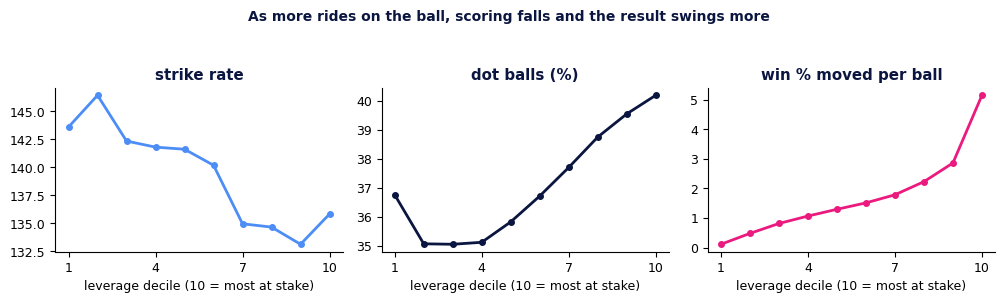

In [3]:
dec = pd.read_csv(ROOT/"reports/validation/outcomes_by_li_decile.csv")
fig, ax = plt.subplots(1, 3, figsize=(10, 2.8))
for a, (c, lab, col) in zip(ax, [("strike_rate","strike rate",BLUE), ("dot_pct","dot balls (%)",NAVY),
                                 ("mean_abs_wpa_pct","win % moved per ball",PINK)]):
    a.plot(range(1,11), dec[c], color=col, lw=2, marker="o", ms=4)
    a.set(xlabel="leverage decile (10 = most at stake)", title=lab, xticks=[1,4,7,10])
fig.suptitle("As more rides on the ball, scoring falls and the result swings more", y=1.06, fontsize=10, fontweight="bold", color=NAVY)
plt.tight_layout(); plt.show()

In [4]:
comp = pd.read_csv(ROOT/"reports/validation/pressure_composition.csv")
comp["innings"] = comp["innings"].map({1:"batting first", 2:"chasing"})
display(comp.round(3))
print(f"\nShare of all pressure balls that come in a chase: {comp[comp.innings=='chasing'].share_of_all_pressure.sum():.0%}")

,innings,phase,balls,mean_li,share_pressure,share_of_all_pressure
0,batting first,death,25958,0.735,0.062,0.040
1,batting first,middle,47392,0.686,0.030,0.035
2,batting first,powerplay,32377,1.077,0.196,0.158
3,chasing,death,18494,1.441,0.350,0.161
4,chasing,middle,45109,0.966,0.263,0.295
5,chasing,powerplay,31631,1.398,0.396,0.312



Share of all pressure balls that come in a chase: 77%


## 2. The rating

Two things are estimated for every player:

- **Level** — how good he is on pressure balls, measured against what an average player does in the
  same situation and credited for the opponent faced.
- **Lift** — how much better (or worse) that is than his *own* everyday standard.

Both are shrunk for sample size by a single hierarchical model, then matches are resampled 1,000
times. The published rating is scaled so **100 is the average qualified player** and 15 points is one
standard deviation. The score behind it is a conservative quartile of the resamples, so nobody is
carried by one or two freak games.

In [5]:
hp = {r: {k: prm[r][k] for k in ("eligible","kappa","kappa_mle","kappa_lo","kappa_hi","sd_ord","sd_level","sd_lift")}
      for r in ("bat","bowl")}
display(pd.DataFrame(hp).rename(columns={"bat":"batters","bowl":"bowlers"}).round(3))
print("kappa = spread of 'lift' talent relative to everyday talent.")
print("Its likelihood is flat from 0 to ~0.8, so we fix it at 0.5: a real but modest pressure effect.")

,batters,bowlers
eligible,110.000,112.000
kappa,0.500,0.500
kappa_mle,0.400,0.600
kappa_lo,0.000,0.000
kappa_hi,0.700,0.900
sd_ord,0.075,0.081
sd_level,0.084,0.091
sd_lift,0.037,0.041


kappa = spread of 'lift' talent relative to everyday talent.
Its likelihood is flat from 0 to ~0.8, so we fix it at 0.5: a real but modest pressure effect.


## 3. The answer

In [6]:
def show(t, cols, title):
    print(title); print("=" * len(title))
    display(t.head(10)[cols].rename(columns={"n_p":"pressure balls","p_top10":"top-10 odds"}).round(2).set_index("rank"))

show(bat,  ["rank","name","team","rating","p_top10","n_p","sr_p","sr_o","avg_p"], "TOP 10 BATTERS UNDER PRESSURE")
show(bowl, ["rank","name","team","rating","p_top10","n_p","econ_p","econ_o","wkts_p"], "TOP 10 BOWLERS UNDER PRESSURE")

TOP 10 BATTERS UNDER PRESSURE


,name,team,rating,top-10 odds,pressure balls,sr_p,sr_o,avg_p
rank,,,,,,,,
1,Vaibhav Sooryavanshi,India,163.0,1.00,210.0,217.70,227.16,65.00
2,Abhishek Sharma,India,137.6,0.96,455.0,167.85,192.83,50.47
3,Tim David,Australia,130.8,0.86,261.0,185.21,178.59,36.62
4,Suryakumar Yadav,Mumbai Indians,128.7,0.82,416.0,158.60,168.58,34.47
5,Priyansh Arya,Punjab Kings,128.2,0.80,146.0,203.45,186.96,24.58
6,Heinrich Klaasen,Sunrisers Hyderabad,125.3,0.72,160.0,173.75,167.07,39.71
7,Finn Allen,New Zealand,121.4,0.60,133.0,163.16,177.87,27.12
8,Andre Russell,West Indies,120.7,0.57,135.0,164.66,175.13,21.90
9,Josh Inglis,Australia,120.1,0.56,181.0,186.74,156.65,42.25


TOP 10 BOWLERS UNDER PRESSURE


,name,team,rating,top-10 odds,pressure balls,econ_p,econ_o,wkts_p
rank,,,,,,,,
1,Jasprit Bumrah,India,141.0,0.98,335.0,7.67,7.17,12.0
2,Sunil Narine,Kolkata Knight Riders,138.8,0.99,236.0,6.15,7.00,14.0
3,Kuldeep Yadav,India,125.8,0.77,267.0,6.46,8.26,18.0
4,Nathan Ellis,Australia,122.6,0.62,181.0,8.83,8.12,7.0
5,Bhuvneshwar Kumar,India,120.4,0.54,634.0,8.02,8.39,25.0
6,Axar Patel,India,119.2,0.52,415.0,7.21,8.01,20.0
7,Josh Hazlewood,Royal Challengers Bengaluru,118.9,0.50,393.0,7.38,8.60,30.0
8,Matheesha Pathirana,Kolkata Knight Riders,117.5,0.42,222.0,9.37,8.75,12.0
9,Varun Chakravarthy,India,117.0,0.44,356.0,7.66,8.08,24.0


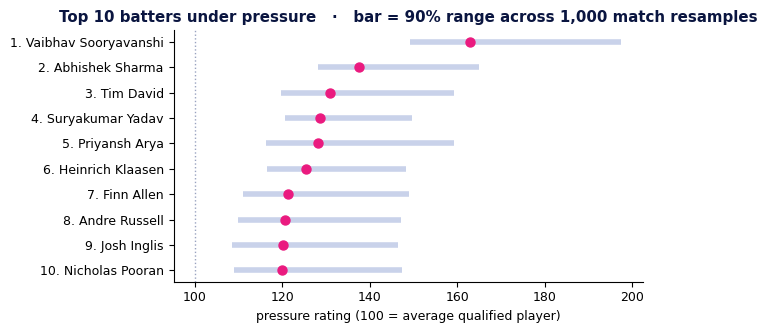

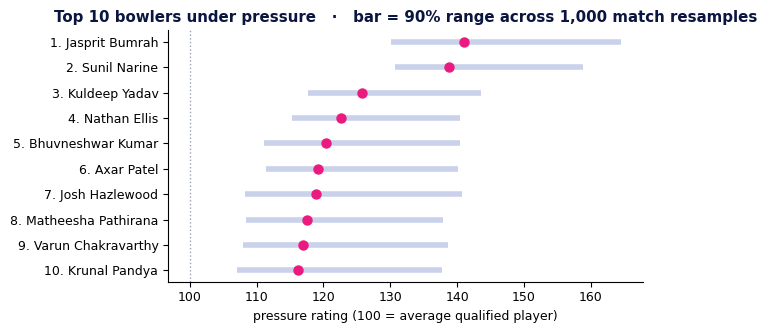

In [7]:
def forest(t, title):
    t = t.head(10).iloc[::-1]; sd = t["score"].std() if False else None
    s = (lambda col: 100 + 15 * col / pd.read_csv(ROOT/f"reports/rankings/{title}_full.csv")["score"].std())
    fig, ax = plt.subplots(figsize=(6.6, 3.4))
    y = np.arange(len(t))
    ax.hlines(y, s(t["lo"]), s(t["hi"]), color="#C9D2EA", lw=4)
    ax.scatter(t["rating"], y, color=PINK, zorder=3, s=42)
    ax.axvline(100, color="#99A3C0", ls=":", lw=1)
    ax.set(yticks=y, xlabel="pressure rating (100 = average qualified player)",
           title=f"Top 10 {title} under pressure   ·   bar = 90% range across 1,000 match resamples")
    ax.set_yticklabels([f"{int(r['rank'])}. {r['name']}" for _, r in t.iterrows()], fontsize=9)
    plt.tight_layout(); plt.show()

forest(bat, "batters"); forest(bowl, "bowlers")

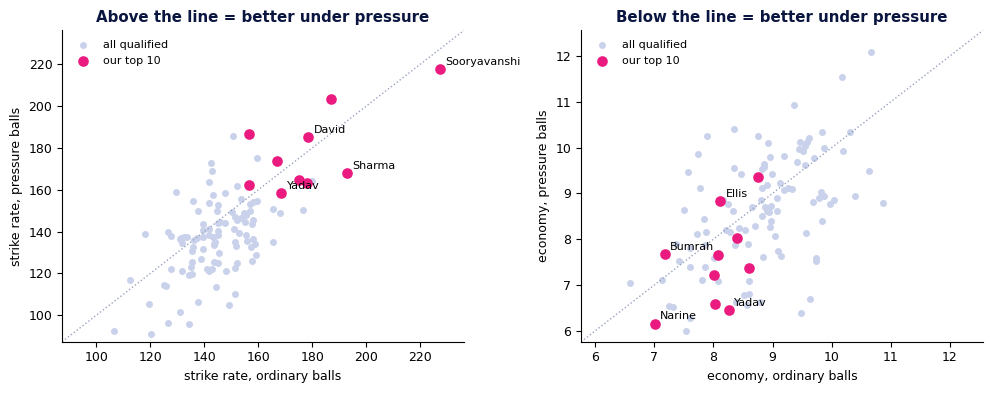

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (t, xo, xp, lab, inv) in zip(ax, [(bat,"sr_o","sr_p","strike rate",False), (bowl,"econ_o","econ_p","economy",True)]):
    a.scatter(t[xo], t[xp], s=16, color="#C9D2EA", label="all qualified")
    a.scatter(t.head(10)[xo], t.head(10)[xp], s=44, color=PINK, zorder=3, label="our top 10")
    lim = [min(t[xo].min(), t[xp].min())*.96, max(t[xo].max(), t[xp].max())*1.04]
    a.plot(lim, lim, color="#99A3C0", ls=":", lw=1)
    for _, r in t.head(4).iterrows():
        a.annotate(r["name"].split()[-1], (r[xo], r[xp]), fontsize=8, xytext=(4,3), textcoords="offset points")
    a.set(xlabel=f"{lab}, ordinary balls", ylabel=f"{lab}, pressure balls", xlim=lim, ylim=lim,
          title=f"{'Below' if inv else 'Above'} the line = better under pressure")
    a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Does it hold up?

Three tests, all reported honestly:

1. **Split-half** — split the matches at random, rate twice, compare.
2. **Held-out prediction** — estimate from half the matches, predict pressure results in the other half.
3. **Sensitivity** — change the pressure cut-off, the weights, the opponent adjustment, the competition.

In [9]:
rows = []
for role, lab in (("batters","batters"), ("bowlers","bowlers")):
    v = val[role]
    rows.append({"": lab,
        "split-half (rating)": v["split_half"]["composite"]["full_sample_reliability"],
        "split-half (raw pressure avg)": v["split_half"]["raw_level"]["full_sample_reliability"],
        "held-out (our rating)": v["holdout_prediction"]["joint_shrunk_level (ours)"],
        "held-out (raw pressure avg)": v["holdout_prediction"]["raw_pressure_average"],
        "held-out (pressure balls only)": v["holdout_prediction"]["pressure_only_shrunk"]})
display(pd.DataFrame(rows).set_index("").round(3))
print("Raw pressure averages barely repeat. Borrowing from a player's ordinary balls is what makes the rating stable.")

,split-half (rating),split-half (raw pressure avg),held-out (our rating),held-out (raw pressure avg),held-out (pressure balls only)
,,,,,
batters,0.546,0.180,0.273,0.160,0.240
bowlers,0.597,0.159,0.225,0.101,0.154


Raw pressure averages barely repeat. Borrowing from a player's ordinary balls is what makes the rating stable.


In [10]:
for role in ("batters","bowlers"):
    s = pd.read_csv(ROOT/f"reports/validation/sensitivity_{role}.csv").drop(columns="variant_top10")
    print(role.upper()); display(s.rename(columns={"spearman_vs_primary":"rank correlation",
        "primary_top10_in_variant_top10":"top 10 kept"}).set_index("variant").round(2))

BATTERS


,players_compared,rank correlation,top 10 kept,primary_top10_in_variant_top20
variant,,,,
LI top 30%,110,0.97,9,10
LI top 15%,85,0.97,9,9
LI top 10%,48,0.92,5,5
no knockout multiplier,110,1.00,10,10
rule-based pressure,57,0.90,5,5
pressure sample only (no borrowing),110,0.49,4,4
level only (no lift),110,0.98,10,10
level 50 / lift 50,110,0.98,9,10
no lift talent (kappa 0),110,0.94,9,10


BOWLERS


,players_compared,rank correlation,top 10 kept,primary_top10_in_variant_top20
variant,,,,
LI top 30%,112,0.96,9,10
LI top 15%,91,0.98,9,10
LI top 10%,57,0.96,6,6
no knockout multiplier,112,1.00,9,10
rule-based pressure,91,0.87,5,8
pressure sample only (no borrowing),112,0.46,3,4
level only (no lift),112,0.98,9,10
level 50 / lift 50,112,0.97,9,10
no lift talent (kappa 0),112,0.92,6,9


### What the rating cannot tell you

- **Being good under pressure is mostly being good.** True pressure and everyday talent correlate at
  about 0.9. That is why ranking on pressure balls alone produces a list that does not repeat.
- **It describes 2022–26; it is not a forecast.** Bowlers' pressure form carries forward; batters'
  barely does, and lift itself does not persist between eras — the same thing baseball found about
  clutch hitting.
- **Places 6 to 10 are close calls** — the bootstrap ranges overlap heavily.
- **Not measured:** fielding, keeping, captaincy, the pitch on the day, the partner at the other end.

## 5. Applying it: the Rajasthan Royals squad

The same per-ball values price each RR contract. "Output worth" converts a player's runs above a
replacement-level player in IPL 2026 into rupees at the rate RR's own wage bill implies.

In [11]:
s = squad.sort_values("surplus_cr", ascending=False)
display(s[["name","salary","runs_above_repl","value_cr","surplus_cr","matches_2026"]].round(1).head(8).set_index("name"))
print("...")
display(s[["name","salary","runs_above_repl","value_cr","surplus_cr","matches_2026"]].round(1).tail(6).set_index("name"))

,salary,runs_above_repl,value_cr,surplus_cr,matches_2026
name,,,,,
Vaibhav Sooryavanshi,1.1,134.6,31.5,30.4,16
Brijesh Sharma,0.3,45.6,10.7,10.4,13
Donovan Ferreira,1.0,32.8,7.7,6.7,15
Yash Raj Punja,0.9,18.2,4.3,3.4,8
Sushant Mishra,0.3,6.0,1.4,1.1,2
Nandre Burger,3.5,18.7,4.4,0.9,13
Shubham Dubey,0.8,6.9,1.6,0.8,7
Sandeep Sharma,4.0,19.2,4.5,0.5,6


...


,salary,runs_above_repl,value_cr,surplus_cr,matches_2026
name,,,,,
Tushar Deshpande,6.5,14.5,3.4,-3.1,7
Ravindra Jadeja,14.0,31.4,7.4,-6.6,14
Riyan Parag,14.0,27.0,6.3,-7.7,14
Yashasvi Jaiswal,18.0,42.5,10.0,-8.0,16
Dhruv Jurel,14.0,25.1,5.9,-8.1,16
Shimron Hetmyer,11.0,9.1,2.1,-8.9,8


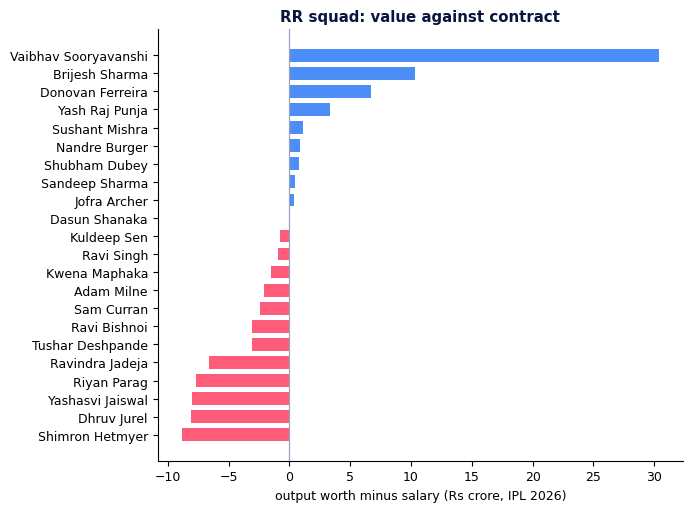

In [12]:
t = s[(s.salary >= 0.5) | (s.surplus_cr.abs() > 1)].sort_values("surplus_cr")
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(t["name"], t["surplus_cr"], color=["#FF5C7A" if v < 0 else BLUE for v in t["surplus_cr"]], height=.7)
ax.axvline(0, color="#99A3C0", lw=.9)
ax.set(xlabel="output worth minus salary (Rs crore, IPL 2026)", title="RR squad: value against contract")
plt.tight_layout(); plt.show()

The interactive version of all of this — a page per player with his pressure splits, phase and
match-up breakdowns, biggest pressure days, the reasoning behind each retain/release call, and a
purse planner — is the dashboard in `dashboard/`.